# 01 - Exploratory data analysis

**Goal of the project:** predict which products a customer will **reorder** in their next Instacart order,
to fill a "Buy it again" shelf.

This notebook looks at the data to answer 4 questions:
1. Is the data clean? (missing values, duplicates)
2. How do customers order? (how often, when, how much)
3. What is reordered?
4. Which signals tell us that a product will be reordered? These become the features.

Run `python -m src.preprocess` and `python -m src.features` before this notebook.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR, PROCESSED_DIR

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=110)

In [2]:
from src.data import load_products, load_table

orders = load_table("orders")
products = load_products()
history = pd.read_parquet(PROCESSED_DIR / "history.parquet")   # prior order items + user + order timing

print(f"orders  : {len(orders):,} rows, {orders['user_id'].nunique():,} users")
print(f"products: {len(products):,}")
print(f"history : {len(history):,} items bought in prior orders")
orders.head()

orders  : 3,421,083 rows, 206,209 users
products: 49,688
history : 32,434,489 items bought in prior orders


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.000
2,473747,1,prior,3,3,12,21.000
3,2254736,1,prior,4,4,7,29.000
4,431534,1,prior,5,4,15,28.000


## 1. Data quality

The Kaggle data has 3 kinds of orders: `prior` (purchase history), and one last order per user,
either `train` (we know what was bought) or `test` (hidden by Kaggle).

In [3]:
print(orders["eval_set"].value_counts().to_string(), "\n")
print("Missing values per column:")
print(orders.isna().sum().to_string(), "\n")
first = orders["order_number"] == 1
print(f"days_since_prior_order is missing for first orders: {orders.loc[first, 'days_since_prior_order'].isna().mean():.0%}")
print(f"... and for the other orders: {orders.loc[~first, 'days_since_prior_order'].isna().mean():.0%}")
print(f"Duplicated (order, product) rows in history: {history.duplicated(['order_id', 'product_id']).sum()}")

eval_set
prior    3214874
train     131209
test       75000 

Missing values per column:
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209 



days_since_prior_order is missing for first orders: 100%
... and for the other orders: 0%


Duplicated (order, product) rows in history: 0


The only missing values are `days_since_prior_order` for the **first order** of each user, which is expected
(there is no previous order). In preprocessing we fill them with 0 to build a timeline of days per user.
There are no duplicated rows.

## 2. How do customers order?

count   206,209.000
mean         16.590
std          16.655
min           4.000
25%           6.000
50%          10.000
75%          20.000
max         100.000


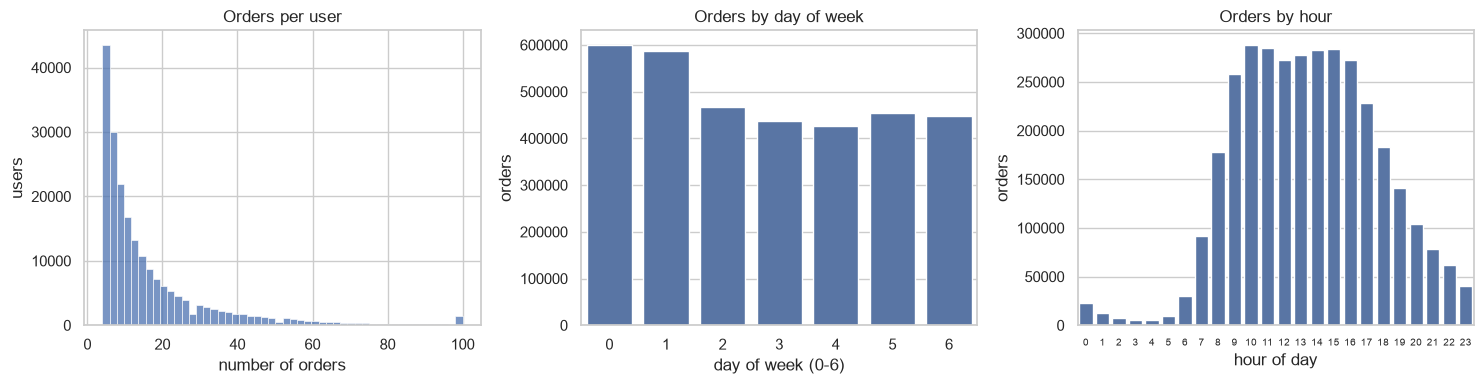

In [4]:
n_orders = orders.groupby("user_id")["order_number"].max()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(n_orders, bins=50, ax=axes[0])
axes[0].set(title="Orders per user", xlabel="number of orders", ylabel="users")
sns.countplot(x=orders["order_dow"], color="C0", ax=axes[1])
axes[1].set(title="Orders by day of week", xlabel="day of week (0-6)", ylabel="orders")
sns.countplot(x=orders["order_hour_of_day"], color="C0", ax=axes[2])
axes[2].set(title="Orders by hour", xlabel="hour of day", ylabel="orders")
axes[2].tick_params(axis="x", labelsize=7)
save(fig, "eda_01_orders.png")
print(n_orders.describe().to_string())

median basket size: 8 products
orders with 30 days since the previous one: 10.8%


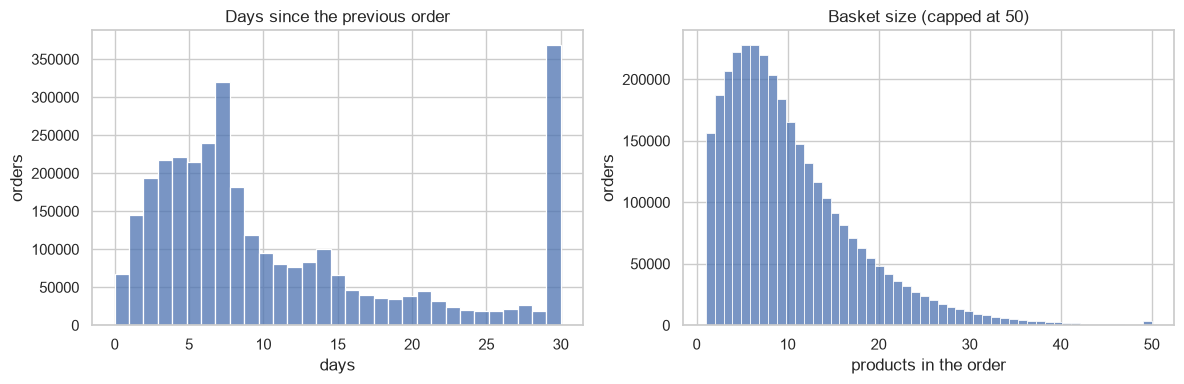

In [5]:
basket = history.groupby("order_id").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders["days_since_prior_order"].dropna(), bins=31, ax=axes[0])
axes[0].set(title="Days since the previous order", xlabel="days", ylabel="orders")
sns.histplot(basket.clip(upper=50), bins=50, ax=axes[1])
axes[1].set(title="Basket size (capped at 50)", xlabel="products in the order", ylabel="orders")
save(fig, "eda_02_timing_and_basket.png")
print(f"median basket size: {basket.median():.0f} products")
print(f"orders with 30 days since the previous one: {(orders['days_since_prior_order'] == 30).mean():.1%}")

* Every user has between 4 and 100 orders, most have fewer than 20.
* Most orders happen during the day, a bit more on days 0 and 1.
* Many customers order **every week** (peak at 7 days). The peak at **30 days** means "30 or more":
  the value is capped in the data.
* A typical basket has about 8 products.

## 3. What is reordered?

Overall share of items that are reorders: 59.0%


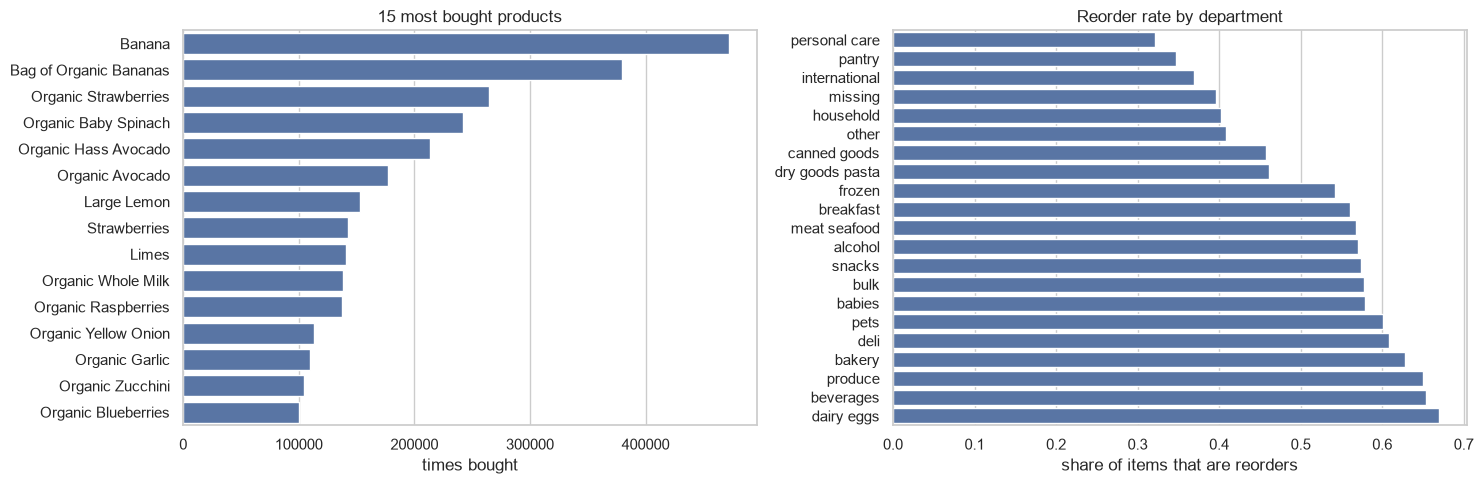

In [6]:
product_info = products.set_index("product_id")
top = history["product_id"].value_counts().head(15)
top.index = product_info.loc[top.index, "product_name"]
department = history["product_id"].map(product_info["department"])   # one department per history row
by_dept = history["reordered"].groupby(department).mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=top.values, y=top.index, color="C0", ax=axes[0])
axes[0].set(title="15 most bought products", xlabel="times bought", ylabel="")
sns.barplot(x=by_dept.values, y=by_dept.index, color="C0", ax=axes[1])
axes[1].set(title="Reorder rate by department", xlabel="share of items that are reorders", ylabel="")
save(fig, "eda_03_products.png")
print(f"Overall share of items that are reorders: {history['reordered'].mean():.1%}")

* Fresh products (bananas, organic fruit and vegetables, milk) are the most bought.
* About 59% of all items are reorders, so customers buy the same things again and again.
* Dairy, beverages and produce are reordered most; personal care and pantry the least.

## 4. Which signals predict a reorder?

We now use the (user, product) table from `src.features` on the **train users only**
(we never look at validation or test users during exploration).
Label = 1 if the user reordered the product in their last order.

In [7]:
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
train = features[features["split"] == "train"]
print(f"{len(train):,} (user, product) pairs, positive rate {train['label'].mean():.1%}")

per_user = train.groupby("user_id").agg(n_true=("label", "sum"))
print(f"users who reorder nothing in their last order: {(per_user['n_true'] == 0).mean():.1%}")

5,948,711 (user, product) pairs, positive rate 9.8%


users who reorder nothing in their last order: 6.6%


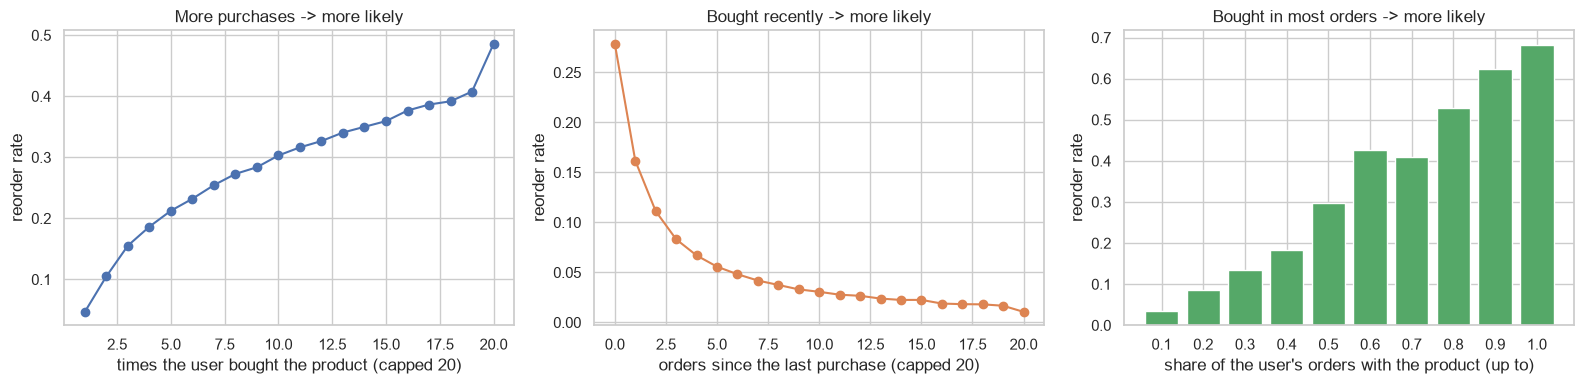

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rate = train.groupby(train["up_n_orders"].clip(upper=20))["label"].mean()
axes[0].plot(rate.index, rate.values, marker="o")
axes[0].set(title="More purchases -> more likely", xlabel="times the user bought the product (capped 20)", ylabel="reorder rate")

rate = train.groupby(train["up_orders_since_last"].clip(upper=20))["label"].mean()
axes[1].plot(rate.index, rate.values, marker="o", color="C1")
axes[1].set(title="Bought recently -> more likely", xlabel="orders since the last purchase (capped 20)", ylabel="reorder rate")

bins = pd.cut(train["up_order_rate"], bins=np.linspace(0, 1, 11), include_lowest=True)
rate = train.groupby(bins, observed=True)["label"].mean()
axes[2].bar(range(len(rate)), rate.values, color="C2")
axes[2].set_xticks(range(len(rate)), [f"{b.right:.1f}" for b in rate.index])
axes[2].set(title="Bought in most orders -> more likely", xlabel="share of the user's orders with the product (up to)", ylabel="reorder rate")
save(fig, "eda_04_reorder_signals.png")

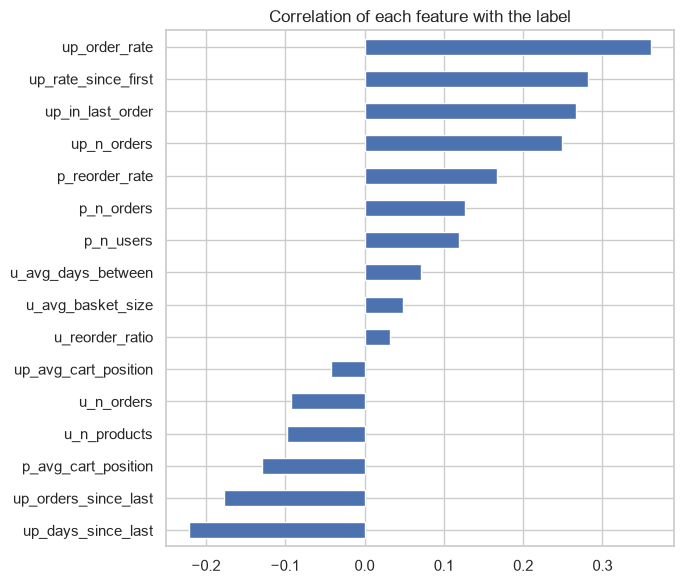

In [9]:
corr = train[[c for c in train.columns if c.startswith(("u_", "p_", "up_"))] + ["label"]].corr()["label"].drop("label")
corr.sort_values().plot.barh(figsize=(7, 6), title="Correlation of each feature with the label")
save(plt.gcf(), "eda_05_feature_correlation.png")

## Conclusions for modeling

* **Frequency and recency** of a (user, product) pair are the strongest signals:
  the more often and the more recently a user bought a product, the more likely they buy it again.
  This gives the `up_*` features.
* Users differ a lot (number of orders, basket size, how often they reorder): `u_*` features.
* Some products are reordered much more than others (milk vs. spices): `p_*` features.
* The label is **imbalanced** (about 10% positive), so accuracy is not a useful metric.
  We use **F1 per order** and tune the probability threshold on validation users.
* About 7% of users reorder nothing in their last order: the shelf may sometimes be empty.